# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Maya Dias, Marilyn Ross, Jiei Ota

**Date:** 11/17/2026

In [14]:
# Your Phase 1 solution to the problem goes here.
import pandas as pd
df = pd.read_csv("data/heart_failure/heart_failure_clinical_records_dataset.csv")
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [15]:
#df.info()
df.isna().sum()
#df['age'] = df['age'].astype(int)
zero_count = (df['age'] == 0).sum()
print(zero_count)
count = ((df['smoking'] != 0) & (df['smoking'] != 1)).sum()
print(count)

#The dataset has 299 patients and 13 columns. There are no missing values, there are no ages of 0, and the binary variable `smoking` contains only 0 and 1. No rows were dropped.The target is `DEATH_EVENT`, and all other columns are used as features. We kept `time` (follow-up days) as a feature. 


0
0


In [16]:
print("Q2")
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.linear_model import LinearRegression

X = df.drop(columns="DEATH_EVENT")
y = df["DEATH_EVENT"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1)

tree = DecisionTreeClassifier(max_depth=3).fit(X_train, y_train)
lm = LinearRegression().fit(X_train, y_train)

tree_pred = tree.predict_proba(X_test)[:, 1]
lm_pred = lm.predict(X_test)

print("tree accuracy:", tree.score(X_test, y_test))
print("linear accuracy:", ((lm_pred > 0.5) == y_test).mean())

#save it
tree_preds = {1: tree_pred}   
lm_preds = {1: lm_pred}
trees = {1: tree}         
lms = {1: lm}
X_test_q2 = X_test   


Q2
tree accuracy: 0.8266666666666667
linear accuracy: 0.8666666666666667


In [17]:
print("Q3")
from sklearn.linear_model import LinearRegression
import pandas as pd
seeds = [2, 43, 100, 150]
for seed in seeds:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=seed)

    tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)
    lm = LinearRegression().fit(X_train, y_train)

    tree_pred = tree.predict_proba(X_test)[:, 1]
    lm_pred = lm.predict(X_test)

    print("seed", seed)
    print("tree accuracy:", tree.score(X_test, y_test))
    print("linear accuracy:", ((lm_pred > 0.5) == y_test).mean())

    trees[seed], lms[seed] = tree, lm
    tree_preds[seed], lm_preds[seed] = tree_pred, lm_pred

# the different trees
for seed in trees:
    print("tree, seed", seed)
    print(export_text(trees[seed], feature_names=list(X.columns)))

coefs = pd.DataFrame({seed: lms[seed].coef_ for seed in lms}, index=X.columns)
coefs["std"] = coefs.std(axis=1)


coefs_sd = coefs.drop(columns="std").mul(X.std(), axis=0)
coefs_sd["std"] = coefs_sd.std(axis=1)
print(coefs_sd.round(3))

Q3
seed 2
tree accuracy: 0.88
linear accuracy: 0.8533333333333334
seed 43
tree accuracy: 0.8
linear accuracy: 0.8266666666666667
seed 100
tree accuracy: 0.8133333333333334
linear accuracy: 0.8133333333333334
seed 150
tree accuracy: 0.8
linear accuracy: 0.8266666666666667
tree, seed 1
|--- time <= 73.50
|   |--- serum_sodium <= 136.50
|   |   |--- serum_creatinine <= 0.85
|   |   |   |--- class: 0
|   |   |--- serum_creatinine >  0.85
|   |   |   |--- class: 1
|   |--- serum_sodium >  136.50
|   |   |--- serum_sodium <= 139.50
|   |   |   |--- class: 1
|   |   |--- serum_sodium >  139.50
|   |   |   |--- class: 1
|--- time >  73.50
|   |--- serum_creatinine <= 1.55
|   |   |--- serum_creatinine <= 0.65
|   |   |   |--- class: 1
|   |   |--- serum_creatinine >  0.65
|   |   |   |--- class: 0
|   |--- serum_creatinine >  1.55
|   |   |--- ejection_fraction <= 22.50
|   |   |   |--- class: 1
|   |   |--- ejection_fraction >  22.50
|   |   |   |--- class: 0

tree, seed 2
|--- time <= 67.50


Q3. Test accuracy was similar across seeds (tree 0.80–0.88, linear 0.81–0.87).

Trees: The root split is always `time`, but the threshold changes (66.5–73.5) and the deeper splits and variables differ a lot from seed to seed

Linear model: Most coefficients keep the same sign and similar size across seeds. The coefficients are stable.


Q4 pt. a


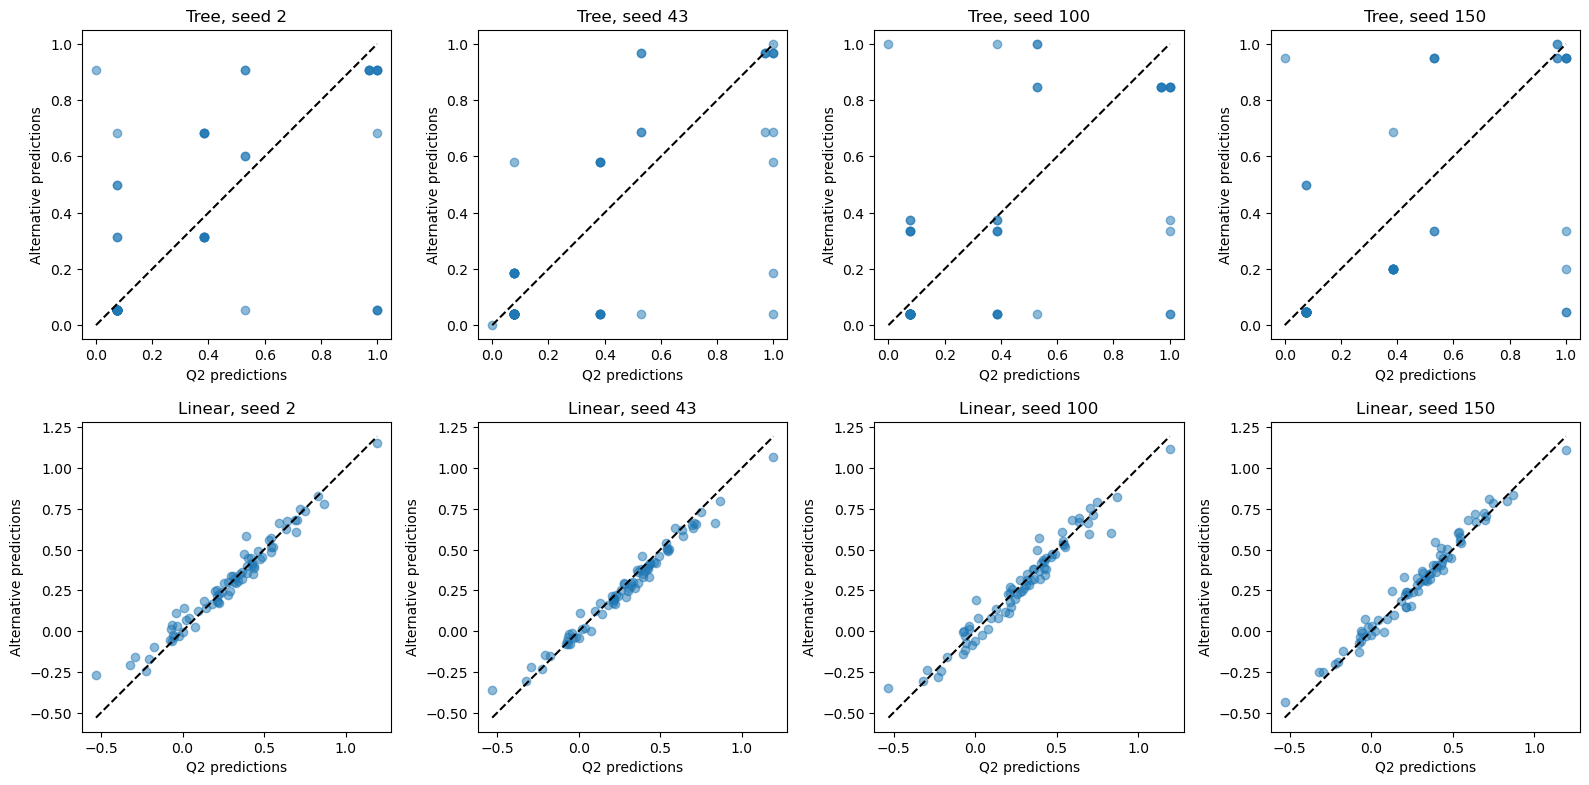

In [18]:
print ("Q4 pt. a")
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

baseline = {"Tree": tree_preds[1], "Linear": lm_preds[1]}

alternatives = {s: {"Tree": trees[s].predict_proba(X_test_q2)[:, 1],
                    "Linear": lms[s].predict(X_test_q2)}
                for s in seeds}

for row, model in enumerate(["Tree", "Linear"]):
    for col, seed in enumerate(seeds):
        x = baseline[model]
        y_alt = alternatives[seed][model]

        ax = axes[row, col]
        ax.scatter(x, y_alt, alpha=0.5)

        low = min(x.min(), y_alt.min())
        high = max(x.max(), y_alt.max())
        ax.plot([low, high], [low, high], "k--")
        ax.set_aspect("equal", adjustable="box")

        ax.set_title(f"{model}, seed {seed}")
        ax.set_xlabel("Q2 predictions")
        ax.set_ylabel("Alternative predictions")

plt.tight_layout()
plt.show()

Q4a. The linear model's predictions are very similar across seeds. the points sit tightly along the y = x line in all four plots. The trees' predictions are not. The points are scattered well away from the line, and many patients get very different predicted probabilities from different seeds. The predictions are also grouped at a few discrete values, because a depth-3 tree has only a handful of leaves.


In [19]:
print("q4b")
import numpy as np
import pandas as pd

corr = pd.DataFrame(
    {model: [np.corrcoef(baseline[model], alternatives[s][model])[0, 1] for s in seeds]
     for model in ["Tree", "Linear"]},
    index=seeds)
corr.index.name = "seed"
print(corr.round(3))


q4b
       Tree  Linear
seed               
2     0.671   0.982
43    0.778   0.991
100   0.641   0.976
150   0.700   0.986


Q4b: The linear models' predictions are almost perfectly correlated with the seed-1 predictions . The trees' predictions are noticeably less correlated (0.641–0.778). So the linear model is very stable across seeds, while the trees are only moderately correlated, which matches the scatterplots in 4a.


In [20]:
print("q4c")
from scipy.stats import linregress

rows = []
for model in ["Tree", "Linear"]:
    for s in seeds:
        r = linregress(baseline[model], alternatives[s][model])
        rows.append({"model": model, "seed": s,
                     "intercept": r.intercept, "slope": r.slope, "R2": r.rvalue**2})

reg = pd.DataFrame(rows)
print(reg.round(3))


q4c
    model  seed  intercept  slope     R2
0    Tree     2      0.095  0.650  0.450
1    Tree    43      0.022  0.766  0.605
2    Tree   100      0.071  0.624  0.411
3    Tree   150      0.043  0.692  0.490
4  Linear     2      0.045  0.893  0.964
5  Linear    43      0.010  0.897  0.982
6  Linear   100      0.011  0.948  0.953
7  Linear   150      0.021  0.972  0.972


Q4c. For the linear models, the intercepts are near 0 (0.01–0.05), the slopes near 1 (0.89–0.97) and R² near 1 (0.95–0.98). For the trees, the slopes are well below 1 (0.62–0.77) and R² is much lower (0.41–0.61), though the intercepts are small. The linear models' predictions barely change across seeds, while the trees' predictions change a lot.


Question 5: 

Linear Models: Yes. Across all five random seeds (1, 2, 43, 100, and 150), the linear model coefficients remain highly stable—key predictors such as `time`, `ejection_fraction`, `serum_creatinine`, and `age` retain the same signs and very similar magnitudes with low standard deviations. Because the learned weights barely shift across splits, the predicted probabilities on the test set also remain strongly consistent (with regression slopes near 1, intercepts near 0, and high $R^2$ values across seeds).

Decision Trees:No. Across the different seeds, the decision trees show substantial structural instability. While `time` is consistently chosen as the root split (with thresholds varying between 66.50 and 73.50), the subsequent splits select completely different features and cutoff values depending on the training split. Moreover, because a shallow tree (`max_depth=3`) outputs a small number of discrete leaf probabilities, minor changes in the training set produce noticeably different predicted values for the same test observations.

Question 6: 

**False** 

**Explanation:** :For decision trees, changing the train/test split substantially alters both the appearance of the tree (different splitting variables and thresholds below the root node) **and** the predictions generated on the test set. Because decision trees are greedy, high-variance estimators—and with `max_depth=3` they partition the feature space into at most 8 coarse leaf regions—shifting a few training observations changes which splits are selected and alters the discrete leaf probabilities, resulting in much weaker agreement ($R^2$ well below 1 and slopes deviating from 1) between predictions across seeds.
For linear models, the global parametric form averages over the entire training sample, so neither the model appearance (coefficients) nor the resulting test predictions change substantially across splits.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 0010e92abaadd48dca30036050d34e6f6ec62c2f
- **AI tool and model used:** ChatGPT 6.2 Sol Light

### *Prompts used

1. Given each of my answers, give me feedback on each one starting with whether it was right or not. 
2. How would you go about improving it (the error).

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Q1 — Mostly correct. Print the missing-value counts and check all binary columns, including DEATH_EVENT.
2. Q2 — Correct as pasted. The split seed is fixed at 1, and you evaluate both models and save their predictions. Add random_state=0 to the tree to make its fit reproducible and match Q3.
3. Q3 — Correct code. You tested four additional seeds and saved the results. Add a sentence summarizing how the trees and linear coefficients changed.
4. Q4a — Correct. You compare predictions for the same Q2 test patients, and the linear predictions lie closer to the \(y=x\) line.
Q4b — Correct. The linear predictions have correlations of 0.976–0.991 with the baseline, while the tree predictions have correlations of 0.641–0.778.
Q4c — Correct. Your regression setup and interpretation of the intercepts, slopes, and \(R^2\) values match the output.
5. Q5 — Mostly correct. Call the linear outputs “predicted values” and say that some of the later tree splits changed.
6. Q6 — Correct for these trees. “False” is supported because both the tree structures and their predictions for the same patients changed across splits.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Just added additional data cleaning for accuracy|
| 2 | Accept | Added for reproducibility |
| 3 | Reject | No changes needed|
| 4 | Reject | No changes needed|
| 5 | Reject | Misread the text uploaded|
| 6 | Reject | No changes needed|








### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [32]:
# Your Phase 2 solution to the problem goes here.
df.info()
print("Missing values by column:")
print(df.isna().sum())

print("Ages recorded as zero:", (df["age"] == 0).sum())

binary_cols = [
    "anaemia", "diabetes", "high_blood_pressure",
    "sex", "smoking", "DEATH_EVENT"
]
print("Invalid binary values by column:")
print((~df[binary_cols].isin([0, 1])).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB
Missing values by 

Q1: The dataset has 299 patients and 13 columns. There are no missing values, there are no ages of 0, and the binary variable smoking contains only 0 and 1. No rows were dropped.The target is DEATH_EVENT, and all other columns are used as features. We kept time (follow-up days) as a feature.

In [33]:
print("Q2")
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.linear_model import LinearRegression

X = df.drop(columns="DEATH_EVENT")
y = df["DEATH_EVENT"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1)

tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)
lm = LinearRegression().fit(X_train, y_train)

tree_pred = tree.predict_proba(X_test)[:, 1]
lm_pred = lm.predict(X_test)

print("tree accuracy:", tree.score(X_test, y_test))
print("linear accuracy:", ((lm_pred > 0.5) == y_test).mean())

#save it
tree_preds = {1: tree_pred}   
lm_preds = {1: lm_pred}
trees = {1: tree}         
lms = {1: lm}
X_test_q2 = X_test   

Q2
tree accuracy: 0.8266666666666667
linear accuracy: 0.8666666666666667


In [34]:
print("Q3")
from sklearn.linear_model import LinearRegression
import pandas as pd
seeds = [2, 43, 100, 150]
for seed in seeds:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=seed)

    tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)
    lm = LinearRegression().fit(X_train, y_train)

    tree_pred = tree.predict_proba(X_test)[:, 1]
    lm_pred = lm.predict(X_test)

    print("seed", seed)
    print("tree accuracy:", tree.score(X_test, y_test))
    print("linear accuracy:", ((lm_pred > 0.5) == y_test).mean())

    trees[seed], lms[seed] = tree, lm
    tree_preds[seed], lm_preds[seed] = tree_pred, lm_pred

# the different trees
for seed in trees:
    print("tree, seed", seed)
    print(export_text(trees[seed], feature_names=list(X.columns)))

coefs = pd.DataFrame({seed: lms[seed].coef_ for seed in lms}, index=X.columns)
coefs["std"] = coefs.std(axis=1)


coefs_sd = coefs.drop(columns="std").mul(X.std(), axis=0)
coefs_sd["std"] = coefs_sd.std(axis=1)
print(coefs_sd.round(3))

Q3
seed 2
tree accuracy: 0.88
linear accuracy: 0.8533333333333334
seed 43
tree accuracy: 0.8
linear accuracy: 0.8266666666666667
seed 100
tree accuracy: 0.8133333333333334
linear accuracy: 0.8133333333333334
seed 150
tree accuracy: 0.8
linear accuracy: 0.8266666666666667
tree, seed 1
|--- time <= 73.50
|   |--- serum_sodium <= 136.50
|   |   |--- serum_creatinine <= 0.85
|   |   |   |--- class: 0
|   |   |--- serum_creatinine >  0.85
|   |   |   |--- class: 1
|   |--- serum_sodium >  136.50
|   |   |--- serum_sodium <= 139.50
|   |   |   |--- class: 1
|   |   |--- serum_sodium >  139.50
|   |   |   |--- class: 1
|--- time >  73.50
|   |--- serum_creatinine <= 1.55
|   |   |--- serum_creatinine <= 0.65
|   |   |   |--- class: 1
|   |   |--- serum_creatinine >  0.65
|   |   |   |--- class: 0
|   |--- serum_creatinine >  1.55
|   |   |--- ejection_fraction <= 22.50
|   |   |   |--- class: 1
|   |   |--- ejection_fraction >  22.50
|   |   |   |--- class: 0

tree, seed 2
|--- time <= 67.50


Q3. Test accuracy was similar across seeds (tree 0.80–0.88, linear 0.81–0.87).

Trees: The root split is always `time`, but the threshold changes (66.5–73.5) and the deeper splits and variables differ a lot from seed to seed

Linear model: Most coefficients keep the same sign and similar size across seeds. The coefficients are stable.

Q4 pt. a


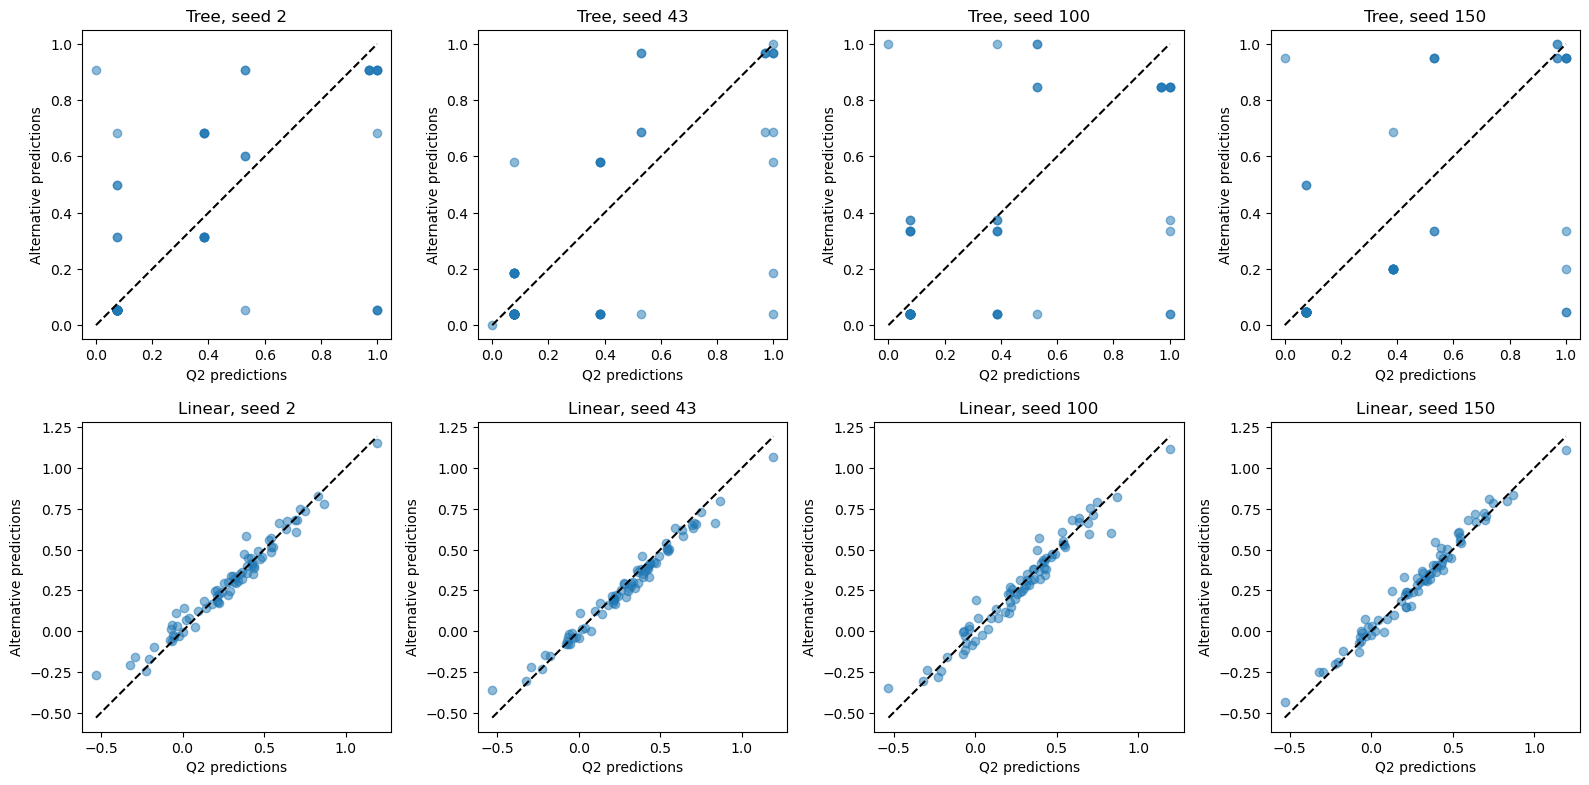

In [28]:
print ("Q4 pt. a")
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

baseline = {"Tree": tree_preds[1], "Linear": lm_preds[1]}

alternatives = {s: {"Tree": trees[s].predict_proba(X_test_q2)[:, 1],
                    "Linear": lms[s].predict(X_test_q2)}
                for s in seeds}

for row, model in enumerate(["Tree", "Linear"]):
    for col, seed in enumerate(seeds):
        x = baseline[model]
        y_alt = alternatives[seed][model]

        ax = axes[row, col]
        ax.scatter(x, y_alt, alpha=0.5)

        low = min(x.min(), y_alt.min())
        high = max(x.max(), y_alt.max())
        ax.plot([low, high], [low, high], "k--")
        ax.set_aspect("equal", adjustable="box")

        ax.set_title(f"{model}, seed {seed}")
        ax.set_xlabel("Q2 predictions")
        ax.set_ylabel("Alternative predictions")

plt.tight_layout()
plt.show()

Q4a. The linear model's predictions are very similar across seeds. the points sit tightly along the y = x line in all four plots. The trees' predictions are not. The points are scattered well away from the line, and many patients get very different predicted probabilities from different seeds. The predictions are also grouped at a few discrete values, because a depth-3 tree has only a handful of leaves.


In [29]:
print("q4b")
import numpy as np
import pandas as pd

corr = pd.DataFrame(
    {model: [np.corrcoef(baseline[model], alternatives[s][model])[0, 1] for s in seeds]
     for model in ["Tree", "Linear"]},
    index=seeds)
corr.index.name = "seed"
print(corr.round(3))

q4b
       Tree  Linear
seed               
2     0.671   0.982
43    0.778   0.991
100   0.641   0.976
150   0.700   0.986


Q4b: The linear models' predictions are almost perfectly correlated with the seed-1 predictions . The trees' predictions are noticeably less correlated (0.641–0.778). So the linear model is very stable across seeds, while the trees are only moderately correlated, which matches the scatterplots in 4a.


In [30]:
print("q4c")
from scipy.stats import linregress

rows = []
for model in ["Tree", "Linear"]:
    for s in seeds:
        r = linregress(baseline[model], alternatives[s][model])
        rows.append({"model": model, "seed": s,
                     "intercept": r.intercept, "slope": r.slope, "R2": r.rvalue**2})

reg = pd.DataFrame(rows)
print(reg.round(3))

q4c
    model  seed  intercept  slope     R2
0    Tree     2      0.095  0.650  0.450
1    Tree    43      0.022  0.766  0.605
2    Tree   100      0.071  0.624  0.411
3    Tree   150      0.043  0.692  0.490
4  Linear     2      0.045  0.893  0.964
5  Linear    43      0.010  0.897  0.982
6  Linear   100      0.011  0.948  0.953
7  Linear   150      0.021  0.972  0.972


Q4c. For the linear models, the intercepts are near 0 (0.01–0.05), the slopes near 1 (0.89–0.97) and R² near 1 (0.95–0.98). For the trees, the slopes are well below 1 (0.62–0.77) and R² is much lower (0.41–0.61), though the intercepts are small. The linear models' predictions barely change across seeds, while the trees' predictions change a lot.

Question 5: 

Linear Models: Yes. Across all five random seeds (1, 2, 43, 100, and 150), the linear model coefficients remain highly stable—key predictors such as `time`, `ejection_fraction`, `serum_creatinine`, and `age` retain the same signs and very similar magnitudes with low standard deviations. Because the learned weights barely shift across splits, the predicted probabilities on the test set also remain strongly consistent (with regression slopes near 1, intercepts near 0, and high $R^2$ values across seeds).

Decision Trees:No. Across the different seeds, the decision trees show substantial structural instability. While `time` is consistently chosen as the root split (with thresholds varying between 66.50 and 73.50), the subsequent splits select completely different features and cutoff values depending on the training split. Moreover, because a shallow tree (`max_depth=3`) outputs a small number of discrete leaf probabilities, minor changes in the training set produce noticeably different predicted values for the same test observations.

Question 6: 

**False** 

**Explanation:** :For decision trees, changing the train/test split substantially alters both the appearance of the tree (different splitting variables and thresholds below the root node) **and** the predictions generated on the test set. Because decision trees are greedy, high-variance estimators—and with `max_depth=3` they partition the feature space into at most 8 coarse leaf regions—shifting a few training observations changes which splits are selected and alters the discrete leaf probabilities, resulting in much weaker agreement ($R^2$ well below 1 and slopes deviating from 1) between predictions across seeds.
For linear models, the global parametric form averages over the entire training sample, so neither the model appearance (coefficients) nor the resulting test predictions change substantially across splits.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The main improvement of AI here is that it really helped with understanding each question and making sure that we had answered all the questions specifically. Additionally, for question 1, when we were asked to clean it, we had that initial cleaning done. AI had given us the advice to improve on that cleaning by just pasting out the sum of each missing value count. That was just a better way of showcasing our findings and the fact that the data was actually already clean and ready to use.

The other big part where AI really helped a lot was when we overlooked a part of question 2, which was adding a random state of 0 to improve reproducibility. I'm also beginning to see that AI is really good at looking through an entire problem as a whole, so it's able to check and make sure that what we had put was what the question was specifically asking for. If we had answered a question but it wasn't the right question, then it would also tell us that information.
The final solution was verified at the end by running through every single code and:
1. We had to make sure that there were no errors regarding syntax.
2. We confirmed our cleaning results and matched it up with what we wrote down.
3. From there, we looked at the model's predictions and ensured that those made sense by comparing with the baseline for the same patients.
The scatter plots were also really useful, as they showed the linear model's predictions being more consistent across the split set in the decision tree predictions.